In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, FloatType, IntegerType
from pathlib import Path


spark = (SparkSession.builder
    .master("local[*]")
    .appName("Practice5_Podcast_Regression")
    .config("spark.driver.memory", "4g")   
    .config("spark.executor.memory", "4g") 
    .getOrCreate())

podcast_schema = StructType([
    StructField("Podcast_Name", StringType(), True),
    StructField("Episode_Title", StringType(), True),
    StructField("Episode_Length", FloatType(), True),
    StructField("Genre", StringType(), True),
    StructField("Host_Popularity", FloatType(), True),
    StructField("Publication_Day", StringType(), True),
    StructField("Publication_Time", StringType(), True),
    StructField("Guest_Popularity", FloatType(), True),
    StructField("Number_of_Ads", IntegerType(), True),
    StructField("Episode_Sentiment", StringType(), True),
    StructField("Listening_Time", FloatType(), True)
])


df_raw = (spark.read
    .option("header", True)
    .schema(podcast_schema)
    .csv("../data/podcast/podcast_dataset.csv"))

print(f"Строк загружено: {df_raw.count()}")
df_raw.printSchema()

Строк загружено: 52500
root
 |-- Podcast_Name: string (nullable = true)
 |-- Episode_Title: string (nullable = true)
 |-- Episode_Length: float (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Host_Popularity: float (nullable = true)
 |-- Publication_Day: string (nullable = true)
 |-- Publication_Time: string (nullable = true)
 |-- Guest_Popularity: float (nullable = true)
 |-- Number_of_Ads: integer (nullable = true)
 |-- Episode_Sentiment: string (nullable = true)
 |-- Listening_Time: float (nullable = true)



In [3]:
print("Распределение по жанрам:")
df_raw.groupBy("Genre").count().orderBy(F.desc("count")).show(5)

print("Распределение по дням недели:")
df_raw.groupBy("Publication_Day").count().orderBy(F.desc("count")).show(7)

Распределение по жанрам:
+---------+-----+
|    Genre|count|
+---------+-----+
| Business| 5559|
|   Health| 5539|
|   Sports| 5521|
|Lifestyle| 5499|
|   Comedy| 5447|
+---------+-----+
only showing top 5 rows
Распределение по дням недели:
+---------------+-----+
|Publication_Day|count|
+---------------+-----+
|       Saturday| 7603|
|        Tuesday| 7531|
|         Sunday| 7522|
|      Wednesday| 7498|
|         Monday| 7460|
|       Thursday| 7455|
|         Friday| 7431|
+---------------+-----+



C:\Users\fedor\AppData\Local\Temp\ipykernel_14404\4017260780.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=genre_pd, x="count", y="Genre", palette="viridis")


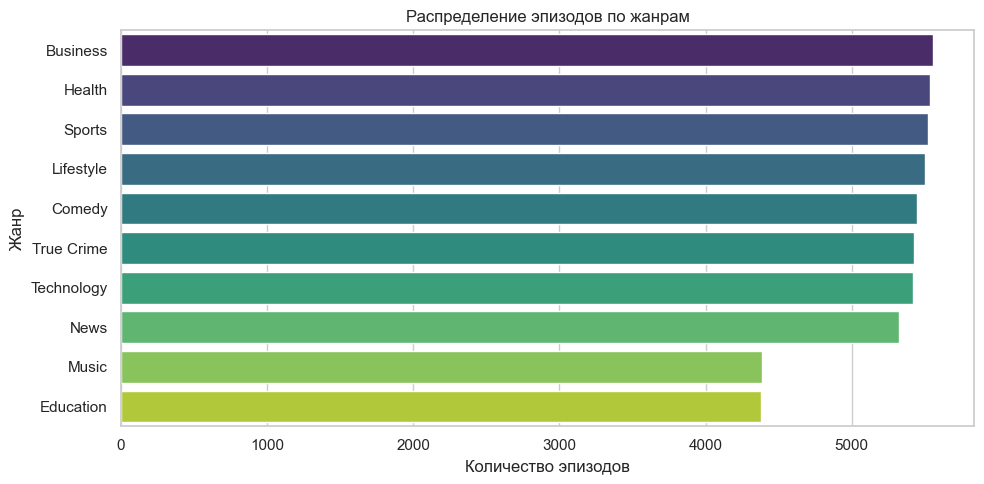

C:\Users\fedor\AppData\Local\Temp\ipykernel_14404\4017260780.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=day_pd, x="Publication_Day", y="count", palette="Blues_d")


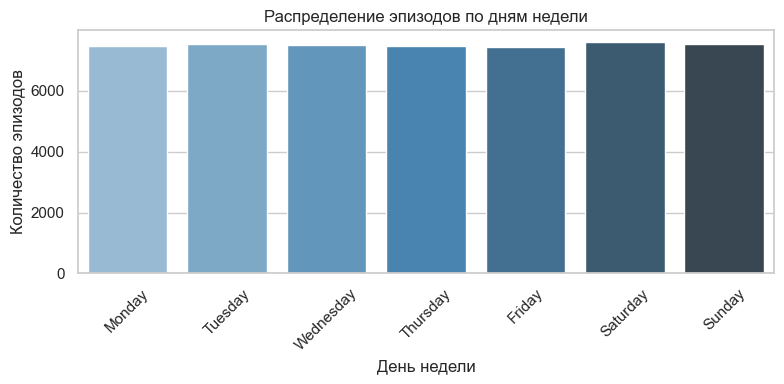

C:\Users\fedor\AppData\Local\Temp\ipykernel_14404\4017260780.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sentiment_pd, x="Episode_Sentiment", y="count", palette="Set2", ax=axes[0])
C:\Users\fedor\AppData\Local\Temp\ipykernel_14404\4017260780.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=time_pd, x="Publication_Time", y="count", palette="Set3", ax=axes[1])


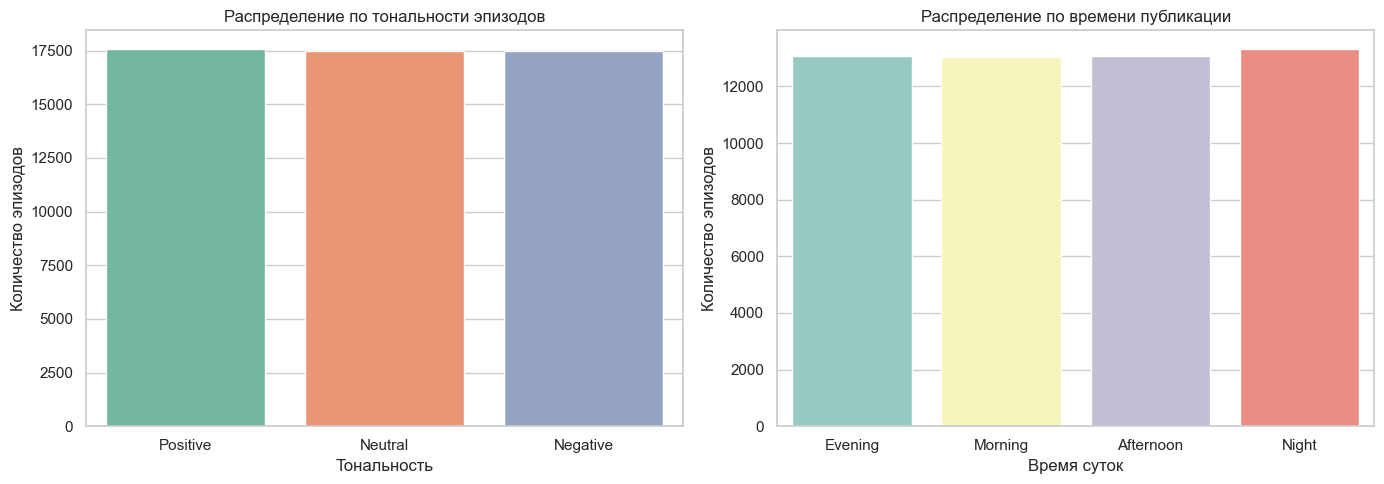

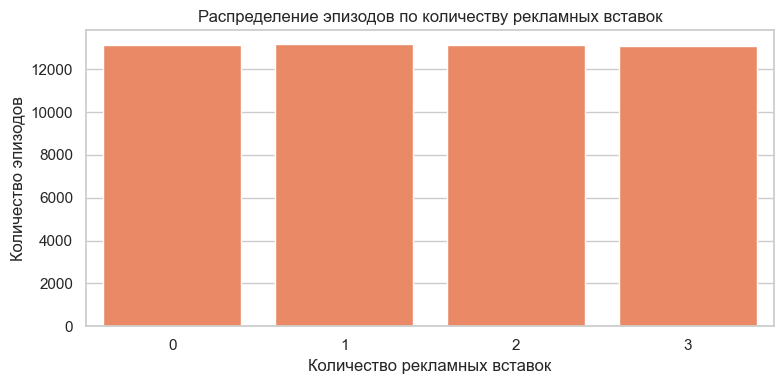

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


genre_pd = df_raw.groupBy("Genre").count().orderBy(F.desc("count")).toPandas()

plt.figure(figsize=(10, 5))
sns.barplot(data=genre_pd, x="count", y="Genre", palette="viridis")
plt.title("Распределение эпизодов по жанрам")
plt.xlabel("Количество эпизодов")
plt.ylabel("Жанр")
plt.tight_layout()
plt.show()


days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_pd = df_raw.groupBy("Publication_Day").count().toPandas()


day_pd['Publication_Day'] = pd.Categorical(day_pd['Publication_Day'], categories=days_order, ordered=True)
day_pd = day_pd.sort_values("Publication_Day")

plt.figure(figsize=(8, 4))
sns.barplot(data=day_pd, x="Publication_Day", y="count", palette="Blues_d")
plt.title("Распределение эпизодов по дням недели")
plt.xlabel("День недели")
plt.ylabel("Количество эпизодов")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sentiment_pd = df_raw.groupBy("Episode_Sentiment").count().toPandas()
sns.barplot(data=sentiment_pd, x="Episode_Sentiment", y="count", palette="Set2", ax=axes[0])
axes[0].set_title("Распределение по тональности эпизодов")
axes[0].set_xlabel("Тональность")
axes[0].set_ylabel("Количество эпизодов")

time_pd = df_raw.groupBy("Publication_Time").count().toPandas()
sns.barplot(data=time_pd, x="Publication_Time", y="count", palette="Set3", ax=axes[1])
axes[1].set_title("Распределение по времени публикации")
axes[1].set_xlabel("Время суток")
axes[1].set_ylabel("Количество эпизодов")

plt.tight_layout()
plt.show()


ads_pd = df_raw.groupBy("Number_of_Ads").count().orderBy("Number_of_Ads").toPandas()

plt.figure(figsize=(8, 4))
sns.barplot(data=ads_pd, x="Number_of_Ads", y="count", color="coral")
plt.title("Распределение эпизодов по количеству рекламных вставок")
plt.xlabel("Количество рекламных вставок")
plt.ylabel("Количество эпизодов")
plt.tight_layout()
plt.show()

In [5]:
SEED = 42
train_df, valid_df, test_df = df_raw.randomSplit([0.6, 0.2, 0.2], seed=SEED)

print(f"Train: {train_df.count()} строк")
print(f"Valid: {valid_df.count()} строк")
print(f"Test:  {test_df.count()} строк")

Train: 31646 строк
Valid: 10347 строк
Test:  10507 строк


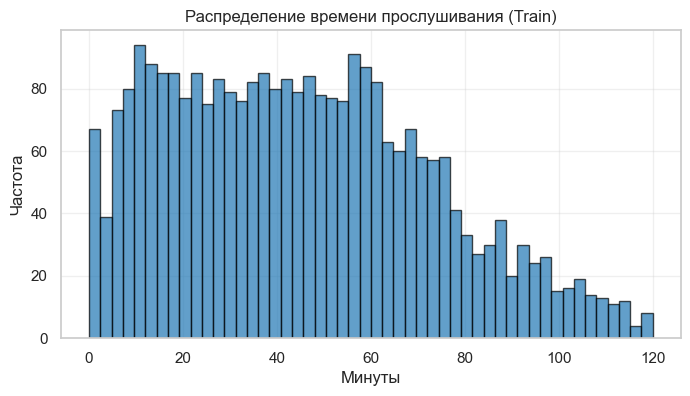

In [6]:
import matplotlib.pyplot as plt


pdf_target = train_df.select("Listening_Time").sample(0.1).toPandas()

plt.figure(figsize=(8, 4))
plt.hist(pdf_target["Listening_Time"], bins=50, color='tab:blue', edgecolor='black', alpha=0.7)
plt.title("Распределение времени прослушивания (Train)")
plt.xlabel("Минуты")
plt.ylabel("Частота")
plt.grid(alpha=0.3)
plt.show()

In [7]:
from pyspark.sql import functions as F


if "Listening_Time" in train_df.columns:
    train_df = train_df.withColumnRenamed("Listening_Time", "label")
    valid_df = valid_df.withColumnRenamed("Listening_Time", "label")
    test_df  = test_df.withColumnRenamed("Listening_Time", "label")

train_df = train_df.dropna(subset=["label"])
valid_df = valid_df.dropna(subset=["label"])
test_df  = test_df.dropna(subset=["label"])

print(f"После удаления пустых Target: Train={train_df.count()}")

num_cols = ["Episode_Length", "Host_Popularity", "Guest_Popularity", "Number_of_Ads"]
cat_cols = ["Genre", "Publication_Day", "Publication_Time", "Episode_Sentiment"]
for c in num_cols:
    train_df = train_df.withColumn(c, F.col(c).cast("double"))
    valid_df = valid_df.withColumn(c, F.col(c).cast("double"))
    test_df  = test_df.withColumn(c, F.col(c).cast("double"))

train_df = train_df.fillna(0.0, subset=num_cols).fillna("unknown", subset=cat_cols)
valid_df = valid_df.fillna(0.0, subset=num_cols).fillna("unknown", subset=cat_cols)
test_df  = test_df.fillna(0.0, subset=num_cols).fillna("unknown", subset=cat_cols)

print("Очистка завершена. Данные готовы к ML.")

После удаления пустых Target: Train=28431
Очистка завершена. Данные готовы к ML.


In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from time import perf_counter

indexers = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep") for c in cat_cols]
encoders = [OneHotEncoder(inputCol=c+"_idx", outputCol=c+"_ohe") for c in cat_cols]


assembler = VectorAssembler(
    inputCols=num_cols + [c+"_ohe" for c in cat_cols], 
    outputCol="features_raw",
    handleInvalid="skip" 
)

scaler = StandardScaler(inputCol="features_raw", outputCol="features")
lr = LinearRegression(featuresCol="features", labelCol="label", maxIter=50)
rf = RandomForestRegressor(
    featuresCol="features_raw", 
    labelCol="label", 
    numTrees=20,       
    maxDepth=6,       
    maxBins=32,       
    seed=42
)

pipeline_lr = Pipeline(stages=indexers + encoders + [assembler, scaler, lr])
pipeline_rf = Pipeline(stages=indexers + encoders + [assembler, rf])


print("Обучение моделей...")
t0 = perf_counter()
model_lr = pipeline_lr.fit(train_df)
print(f"Линейная регрессия обучена за {perf_counter() - t0:.2f} сек")

t0 = perf_counter()
model_rf = pipeline_rf.fit(train_df)
print(f"Случайный лес обучен за {perf_counter() - t0:.2f} сек")


pred_lr = model_lr.transform(valid_df)
pred_rf = model_rf.transform(valid_df)

def evaluate_model(predictions, model_name):
    rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse").evaluate(predictions)
    mae = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae").evaluate(predictions)
    r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2").evaluate(predictions)
    print(f"{model_name:20} | RMSE: {rmse:6.2f} | MAE: {mae:6.2f} | R2: {r2:6.3f}")

print("\n--- Оценка на Valid ---")
evaluate_model(pred_lr, "Лин. Регрессия")
evaluate_model(pred_rf, "Случайный лес")

Обучение моделей...
Линейная регрессия обучена за 3.83 сек
Случайный лес обучен за 4.37 сек

--- Оценка на Valid ---
Лин. Регрессия       | RMSE:  18.20 | MAE:  13.34 | R2:  0.546
Случайный лес        | RMSE:  15.97 | MAE:  12.52 | R2:  0.650


--- Итоговая оценка на TEST (Случайный лес) ---
Случайный лес        | RMSE:  15.86 | MAE:  12.46 | R2:  0.660


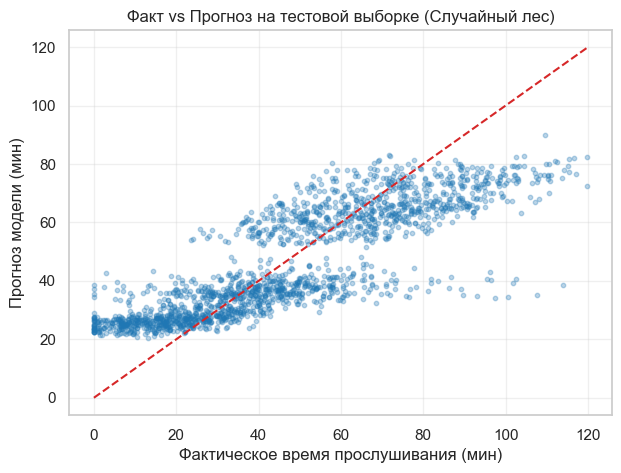

In [ ]:
import matplotlib.pyplot as plt

best_model = model_rf
best_name = "Случайный лес"

print(f"--- Итоговая оценка на TEST ({best_name}) ---")
pred_test = best_model.transform(test_df)
evaluate_model(pred_test, best_name)

pdf_test = pred_test.select("label", "prediction").sample(0.2, seed=42).toPandas()

plt.figure(figsize=(7, 5))
plt.scatter(pdf_test["label"], pdf_test["prediction"], alpha=0.3, s=10, color='tab:blue')
limit = max(pdf_test["label"].max(), pdf_test["prediction"].max())
plt.plot([0, limit], [0, limit], color='tab:red', linestyle='--') 
plt.xlabel("Фактическое время прослушивания (мин)")
plt.ylabel("Прогноз модели (мин)")
plt.title(f"Факт vs Прогноз на тестовой выборке ({best_name})")
plt.grid(alpha=0.3)
plt.show()